Student Performance Dashboard

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [12]:
data = pd.read_csv(r"C:\Users\92348\Desktop\MLBench\Day11_ML\student_performance.csv")
df = pd.DataFrame(data)
df.head()


,Student_ID,Name,Age,Program,Python,Mathematics,Statistics,Machine_Learning,Attendance
0,S001,Ali Khan,20,AI,85,78,92,88,95
1,S002,Sara Ahmed,21,AI,72,75,70,80,90
2,S003,Ahmed Raza,22,SE,90,88,91,93,96
3,S004,Fatima Noor,20,DS,65,70,68,72,85
4,S005,Usman Ali,21,AI,78,82,80,76,88


How many students are in the dataset?

In [ ]:
#total students are in the dataset
df.shape[0]

20

What is the average score for each subject?

In [14]:
avg_python =df['Python'].mean()
avg_math = df['Mathematics'].mean()
avg_Stat= df['Statistics'].mean()
avg_ML = df['Machine_Learning'].mean()
print("Average Python Score:", avg_python)
print("Average Mathematics Score:", avg_math)
print("Average Statistics Score:", avg_Stat)
print("Average Machine Learning Score:", avg_ML)

Average Python Score: 78.9
Average Mathematics Score: 79.5
Average Statistics Score: 80.6
Average Machine Learning Score: 82.6


Who are the Top 5 performing students?

In [16]:
top_five_students = df.nlargest(5, ['Python', 'Mathematics', 'Statistics', 'Machine_Learning'])
print("Top 5 Students based on their scores:")
print(top_five_students[['Name', 'Python', 'Mathematics', 'Statistics', 'Machine_Learning']])

Top 5 Students based on their scores:
            Name  Python  Mathematics  Statistics  Machine_Learning
17    Laiba Khan      97           95          98                99
5   Ayesha Malik      95           94          96                97
11   Noor Fatima      92           90          93                95
2     Ahmed Raza      90           88          91                93
15     Hira Shah      89           91          88                90


Which students need improvement?

In [19]:
#Those students who are below than average in all subjects need to improvements
below_average_students = df[(df['Python'] < avg_python) & (df['Mathematics'] < avg_math) & (df['Statistics'] < avg_Stat) & (df['Machine_Learning'] < avg_ML)]
print("Python Average marks:", avg_python)
print("Mathematics Average marks:", avg_math)
print("Statistics Average marks:", avg_Stat)
print("Machine Learning Average marks:", avg_ML)
print("================================\n===============================")
print("Students below average in all subjects:")
print(below_average_students[['Name', 'Python', 'Mathematics', 'Statistics', 'Machine_Learning']])


Python Average marks: 78.9
Mathematics Average marks: 79.5
Statistics Average marks: 80.6
Machine Learning Average marks: 82.6
Students below average in all subjects:
              Name  Python  Mathematics  Statistics  Machine_Learning
1       Sara Ahmed      72           75          70                80
3      Fatima Noor      65           70          68                72
6     Hassan Tariq      55           60          58                62
8      Bilal Ahmed      73           77          75                79
10  Hamza Siddiqui      69           71          74                70
12     Talha Javed      76           74          78                80
14      Danish Ali      61           65          63                67
16     Omar Farooq      74           72          76                78
18        Abdullah      68           66          70                72


Which subject has the highest class average?

In [21]:
if avg_python > avg_ML and avg_python > avg_Stat and avg_python > avg_math:
    print("Python has Highest average:", avg_python)

elif avg_ML > avg_python and avg_ML > avg_Stat and avg_ML > avg_math:
    print("ML has Highest average:", avg_ML)

elif avg_Stat > avg_python and avg_Stat > avg_ML and avg_Stat > avg_math:
    print("Statistics has Highest average:", avg_Stat)

elif avg_math > avg_python and avg_math > avg_ML and avg_math > avg_Stat:
    print("Math has Highest average:", avg_math)


ML has Highest average: 82.6


In [ ]:
#highest average using max function to cross verfiy
highest_average = max(avg_python, avg_math, avg_Stat, avg_ML)
print("Highest class average is:", highest_average)

Highest class average is: 82.6


In [ ]:
#Create a new column named Average_Score by calculating the average marks across all subjects.
df['Average_Score'] = df[['Python', 'Mathematics', 'Statistics', 'Machine_Learning']].mean(axis=1)


In [ ]:
#new column named Performance based on Average_Score

df['Performance'] = pd.cut(df['Average_Score'], bins=[0, 70, 80, 90, 100], labels=['Needs Improvement', 'Average', 'Good', 'Excellent'])
df.drop(columns=['Average'], inplace=True)  
df.to_csv('cleaned_student_performance.csv', index=False)

In [56]:
#new CSV cleaned File
data2 = pd.read_csv(r"C:\Users\92348\Desktop\MLBench\Day11_ML\cleaned_student_performance.csv")
df2 = pd.DataFrame(data2)
df2.head()

,Student_ID,Name,Age,Program,Python,Mathematics,Statistics,Machine_Learning,Attendance,Performance,Average_Score
0,S001,Ali Khan,20,AI,85,78,92,88,95,Good,85.75
1,S002,Sara Ahmed,21,AI,72,75,70,80,90,Average,74.25
2,S003,Ahmed Raza,22,SE,90,88,91,93,96,Excellent,90.50
3,S004,Fatima Noor,20,DS,65,70,68,72,85,Needs Improvement,68.75
4,S005,Usman Ali,21,AI,78,82,80,76,88,Average,79.00


Data Visualization

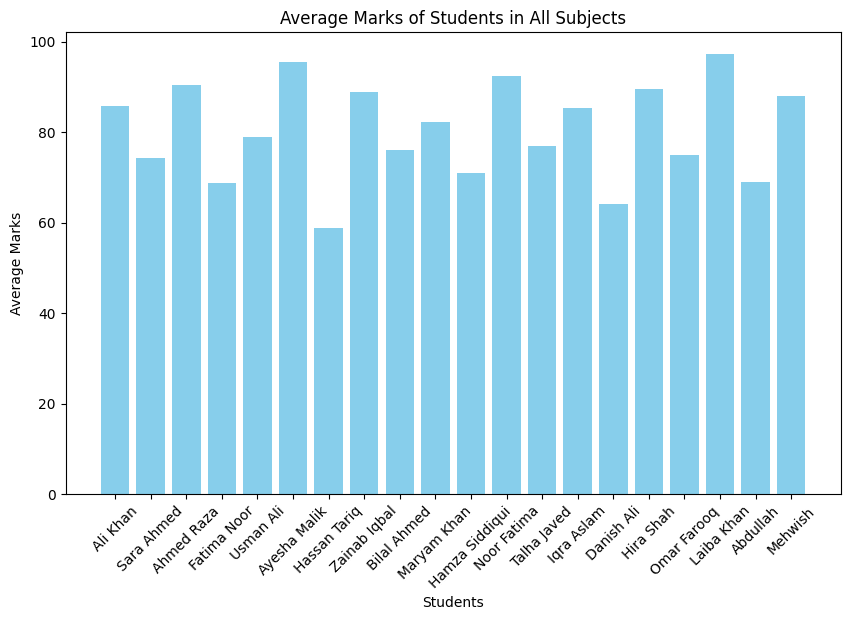

In [42]:
#Bar chart showing the average marks of each student in all subjects
df['Average'] = df[['Python', 'Mathematics', 'Statistics', 'Machine_Learning']].mean(axis=1)
plt.figure(figsize=(10, 6))
plt.bar(df['Name'], df['Average'], color='skyblue')
plt.xlabel('Students')
plt.ylabel('Average Marks')
plt.title('Average Marks of Students in All Subjects')
plt.xticks(rotation=45)
plt.show()

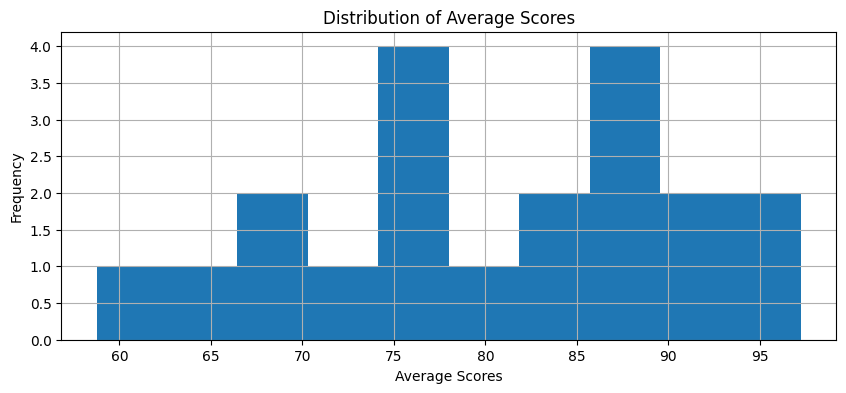

In [32]:
#Histogram showing the distribution of Average Scores

df['Average'] = df[['Python', 'Mathematics', 'Statistics', 'Machine_Learning']].mean(axis=1)
df['Average'].hist(bins=10, figsize=(10, 4))
plt.xlabel('Average Scores')
plt.ylabel('Frequency')
plt.title('Distribution of Average Scores')
plt.show()

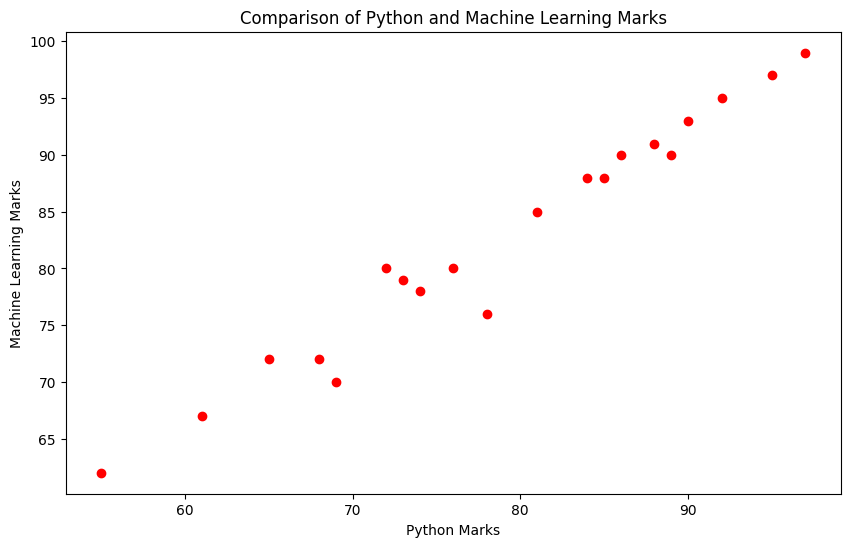

In [35]:
#Scatter plot comparing Python and Machine Learning marks
plt.figure(figsize=(10, 6))
plt.scatter(df['Python'], df['Machine_Learning'], color='red')
plt.xlabel('Python Marks')
plt.ylabel('Machine Learning Marks')
plt.title('Comparison of Python and Machine Learning Marks')
plt.show()

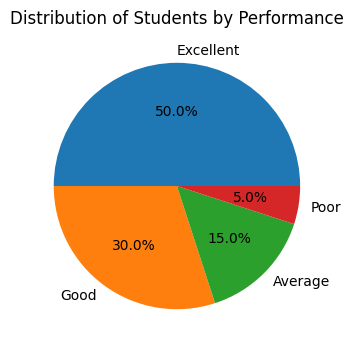

In [36]:
#Pie chart showing the distribution of students by Performance category.
df['Performance'] = pd.cut(df['Average'], bins=[0, 60, 70, 80, 100], labels=['Poor', 'Average', 'Good', 'Excellent'])
df['Performance'].value_counts().plot(kind='pie', autopct='%1.1f%%', figsize=(4, 4))
plt.title('Distribution of Students by Performance')
plt.ylabel('')
plt.show()

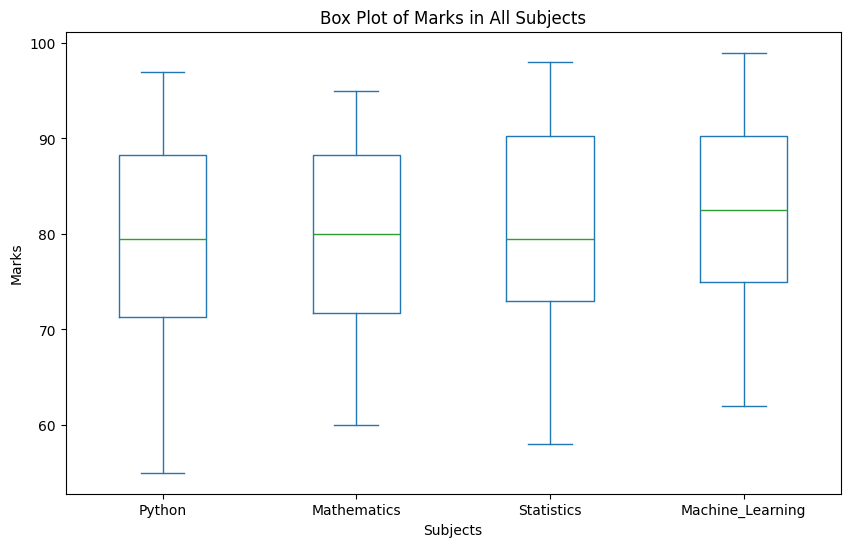

In [43]:
#Box plot to visualize the spread of marks in all subjects.
df[['Python', 'Mathematics', 'Statistics', 'Machine_Learning']].plot(kind='box', figsize=(10, 6))
plt.title('Box Plot of Marks in All Subjects')
plt.xlabel('Subjects')
plt.ylabel('Marks')
plt.show()